# Cross-Sectional Stock Return Prediction

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf

In [3]:
#Chosen stocks
tickers = [
    "AAPL", "MSFT", "GOOGL", "AMZN", "META",
    "NVDA", "JPM", "XOM", "JNJ", "PG"
]

In [4]:
#Download data
prices = yf.download(tickers, start='2015-01-01', end = '2026-01-01', auto_adjust=True)
prices.head()

[*********************100%***********************]  10 of 10 completed


Price           Close                                                       \
Ticker           AAPL     AMZN      GOOGL        JNJ        JPM       META   
Date                                                                         
2015-01-02  24.171755  15.4260  26.227922  75.737373  45.838100  77.705750   
2015-01-05  23.490797  15.1095  25.728180  75.208397  44.415062  76.457695   
2015-01-06  23.493011  14.7645  25.093222  74.838829  43.263409  75.427574   
2015-01-07  23.822437  14.9210  25.019423  76.490997  43.329433  75.427574   
2015-01-08  24.737743  15.0230  25.106592  77.092422  44.297688  77.438324   

Price                                                  ...     Volume  \
Ticker           MSFT      NVDA         PG        XOM  ...       AAPL   
Date                                                   ...              
2015-01-02  39.607166  0.481884  64.642052  56.777905  ...  212818400   
2015-01-05  39.242950  0.473745  64.334747  55.224358  ...  257142000   
2015-01-06  38.666981  0.459382  64.041695  54.930771  ...  263188400   
2015-01-07  39.158234  0.458185  64.377617  55.487354  ...  160423600   
2015-01-08  40.310219  0.475420  65.113808  56.410923  ...  237458000   

Price                                                                  \
Ticker          AMZN     GOOGL      JNJ       JPM      META      MSFT   
Date                                                                    
2015-01-02  55664000  26480000  5753600  12600000  18177500  27913900   
2015-01-05  55484000  41182000  8079300  20100600  26452200  39673900   
2015-01-06  70380000  54456000  7428000  29074100  27399300  36447900   
2015-01-07  52806000  46918000  7931700  23843200  22045300  29114100   
2015-01-08  61768000  73054000  9916000  16971100  23961000  29645200   

Price                                     
Ticker           NVDA       PG       XOM  
Date                                      
2015-01-02  113680000  7251400  10220400  
2015-01-05  197952000  8626100  18502400  
2015-01-06  197764000  7791200  16670700  
2015-01-07  321808000  5986600  13590700  
2015-01-08  283780000  6823300  15487500  

[5 rows x 50 columns]

In [5]:
close = prices["Close"] #Closing prices (daily)
prices_monthly = close.resample("ME").last() #Month's end closing prices
returns_monthly = prices_monthly.pct_change() #Calculate returns

returns_monthly.head()

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,META,MSFT,NVDA,PG,XOM
Date,,,,,,,,,,
2015-01-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-02-28,0.100776,0.072293,0.046656,0.030832,0.126885,0.040311,0.093120,0.153383,0.009965,0.020435
2015-03-31,-0.031372,-0.021202,-0.014095,-0.018632,-0.011423,0.041155,-0.072748,-0.051224,-0.037472,-0.039982
2015-04-30,0.005786,0.133513,-0.010691,-0.013916,0.051180,-0.041961,0.196262,0.060679,-0.021851,0.027882
2015-05-31,0.045339,0.017663,-0.006287,0.016837,0.039836,0.005332,-0.030334,0.001461,-0.014086,-0.016771


In [6]:
#target variable
future_returns = returns_monthly.shift(-1)
future_returns.head()

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,META,MSFT,NVDA,PG,XOM
Date,,,,,,,,,,
2015-01-31,0.100776,0.072293,0.046656,0.030832,0.126885,0.040311,0.093120,0.153383,0.009965,0.020435
2015-02-28,-0.031372,-0.021202,-0.014095,-0.018632,-0.011423,0.041155,-0.072748,-0.051224,-0.037472,-0.039982
2015-03-31,0.005786,0.133513,-0.010691,-0.013916,0.051180,-0.041961,0.196262,0.060679,-0.021851,0.027882
2015-04-30,0.045339,0.017663,-0.006287,0.016837,0.039836,0.005332,-0.030334,0.001461,-0.014086,-0.016771
2015-05-31,-0.037227,0.011323,-0.009682,-0.026763,0.030100,0.083091,-0.057832,-0.091279,-0.001913,-0.023474


## Feature Engineering

In [7]:
# features_df = future_returns.reset_index().melt(
#     id_vars="Date",
#     var_name="Ticker",
#     value_name="Future Returns"
# )

# features_df.head()


### Momentum

The momentum at time $t$ is given by $$ \frac{P_{t-1}}{P_{t-12}} - 1 $$

measuring how much the stock has increased or decreaed over the past year

In [8]:
momentum = prices_monthly.shift(1) / prices_monthly.shift(12) - 1

In [9]:
momentum_df = momentum.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Momentum"
)

features_df = momentum_df.copy()
features_df.tail()

,Date,Ticker,Momentum
1315,2025-08-31,XOM,-0.028234
1316,2025-09-30,XOM,0.010258
1317,2025-10-31,XOM,0.000400
1318,2025-11-30,XOM,-0.003652
1319,2025-12-31,XOM,0.117174


### Volatility

In [10]:
volatility = prices_monthly.rolling(12).std()

In [11]:
volatility_df = volatility.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Volatility"
)
features_df['Volatility'] = volatility_df['Volatility']
features_df.tail()

,Date,Ticker,Momentum,Volatility
1315,2025-08-31,XOM,-0.028234,4.983385
1316,2025-09-30,XOM,0.010258,4.959671
1317,2025-10-31,XOM,0.000400,5.077395
1318,2025-11-30,XOM,-0.003652,5.302773
1319,2025-12-31,XOM,0.117174,5.991955


### Beta

In [12]:
#Download market data
market = yf.download(
    "^GSPC",
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True
)

market_prices = market["Close"].resample("ME").last()
market_returns = market_prices.squeeze().pct_change()

[*********************100%***********************]  1 of 1 completed


In [13]:
returns_monthly = returns_monthly.astype(float)
market_returns = market_returns.astype(float)


In [14]:
#Calculate betas
betas = {}
for ticker in tickers:
    betas[ticker] = returns_monthly[ticker].rolling(12).cov(market_returns) / market_returns.rolling(12).var()

betas

{'AAPL': Date
 2015-01-31         NaN
 2015-02-28         NaN
 2015-03-31         NaN
 2015-04-30         NaN
 2015-05-31         NaN
                 ...   
 2025-08-31    0.368904
 2025-09-30    0.493242
 2025-10-31    0.463810
 2025-11-30    0.389569
 2025-12-31    0.619201
 Freq: ME, Length: 132, dtype: float64,
 'MSFT': Date
 2015-01-31         NaN
 2015-02-28         NaN
 2015-03-31         NaN
 2015-04-30         NaN
 2015-05-31         NaN
                 ...   
 2025-08-31    1.342135
 2025-09-30    1.298322
 2025-10-31    1.202573
 2025-11-30    1.352793
 2025-12-31    1.473587
 Freq: ME, Length: 132, dtype: float64,
 'GOOGL': Date
 2015-01-31         NaN
 2015-02-28         NaN
 2015-03-31         NaN
 2015-04-30         NaN
 2015-05-31         NaN
                 ...   
 2025-08-31    0.879256
 2025-09-30    1.034016
 2025-10-31    1.122436
 2025-11-30    1.435124
 2025-12-31    1.908740
 Freq: ME, Length: 132, dtype: float64,
 'AMZN': Date
 2015-01-31         NaN
 2015-0

In [15]:
betas_predf = pd.DataFrame(betas)
betas_df = betas_predf.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Beta"
)

betas_df

,Date,Ticker,Beta
0,2015-01-31,AAPL,NaN
1,2015-02-28,AAPL,NaN
2,2015-03-31,AAPL,NaN
3,2015-04-30,AAPL,NaN
4,2015-05-31,AAPL,NaN
...,...,...,...
1315,2025-08-31,PG,0.552708
1316,2025-09-30,PG,0.501825
1317,2025-10-31,PG,0.454633
1318,2025-11-30,PG,0.190866


In [16]:
features_df['Beta'] = betas_df['Beta']
features_df.tail()

,Date,Ticker,Momentum,Volatility,Beta
1315,2025-08-31,XOM,-0.028234,4.983385,0.552708
1316,2025-09-30,XOM,0.010258,4.959671,0.501825
1317,2025-10-31,XOM,0.000400,5.077395,0.454633
1318,2025-11-30,XOM,-0.003652,5.302773,0.190866
1319,2025-12-31,XOM,0.117174,5.991955,0.057402


### Current Size \& Value

Note: need to be adjusted into historical data for backtesting, but temporarily uses current data

In [17]:
market_caps = {}
pe_ratios = {}

for ticker in tickers:
    info = yf.Ticker(ticker).info
    market_caps[ticker] = info.get('marketCap')
    pe_ratios[ticker] = info.get('trailingPE')

In [18]:
market_caps

{'AAPL': 5065640247296,
 'MSFT': 3945415311360,
 'GOOGL': 3920672325632,
 'AMZN': 2730015850496,
 'META': 1585722294272,
 'NVDA': 5262596898816,
 'JPM': 891723972608,
 'XOM': 739774103552,
 'JNJ': 646916538368,
 'PG': 369060577280}

In [19]:
#Use log market cap instead for feature
log_market_caps = {
    ticker : float(np.log(cap))
    for ticker, cap in market_caps.items()
    if cap is not None
}

log_market_caps

{'AAPL': 29.25350165181948,
 'MSFT': 29.003575340061747,
 'GOOGL': 28.997284266665297,
 'AMZN': 28.635328531151053,
 'META': 28.09206112562057,
 'NVDA': 29.291645727844205,
 'JPM': 27.516422473888706,
 'XOM': 27.329610711071368,
 'JNJ': 27.19548312524074,
 'PG': 26.634226633583623}

In [20]:
#P/E ratios to Earnings yield

earnings_yield = {
    ticker : 1 / pe
    for ticker, pe in pe_ratios.items()
    if pe is not None and pe > 0
}

earnings_yield

{'AAPL': 0.025122443018907707,
 'MSFT': 0.03431012662701194,
 'GOOGL': 0.062168567708937215,
 'AMZN': 0.04911102175087865,
 'META': 0.04725970730929031,
 'NVDA': 0.03629439326027635,
 'JPM': 0.07099674891687359,
 'XOM': 0.04318826108513097,
 'JNJ': 0.024522754099505585,
 'PG': 0.04170068573858649}

In [21]:
curr_df = pd.DataFrame({
    "Ticker" : list(log_market_caps.keys()),
    "Size" : log_market_caps.values(),
    "Value" : earnings_yield.values()
})

curr_df.head()

,Ticker,Size,Value
0,AAPL,29.253502,0.025122
1,MSFT,29.003575,0.034310
2,GOOGL,28.997284,0.062169
3,AMZN,28.635329,0.049111
4,META,28.092061,0.047260


In [22]:
features_df = features_df.merge(
    curr_df,
    on="Ticker",
    how="left"
)

features_df.tail()

,Date,Ticker,Momentum,Volatility,Beta,Size,Value
1315,2025-08-31,XOM,-0.028234,4.983385,0.552708,27.329611,0.043188
1316,2025-09-30,XOM,0.010258,4.959671,0.501825,27.329611,0.043188
1317,2025-10-31,XOM,0.000400,5.077395,0.454633,27.329611,0.043188
1318,2025-11-30,XOM,-0.003652,5.302773,0.190866,27.329611,0.043188
1319,2025-12-31,XOM,0.117174,5.991955,0.057402,27.329611,0.043188


In [23]:
target_df = future_returns.reset_index().melt(
    id_vars="Date",
    var_name="Ticker",
    value_name="Future Returns"
)

features_df['Future Returns'] = target_df['Future Returns']
features_df.tail()

,Date,Ticker,Momentum,Volatility,Beta,Size,Value,Future Returns
1315,2025-08-31,XOM,-0.028234,4.983385,0.552708,27.329611,0.043188,-0.013474
1316,2025-09-30,XOM,0.010258,4.959671,0.501825,27.329611,0.043188,0.014279
1317,2025-10-31,XOM,0.000400,5.077395,0.454633,27.329611,0.043188,0.022507
1318,2025-11-30,XOM,-0.003652,5.302773,0.190866,27.329611,0.043188,0.038130
1319,2025-12-31,XOM,0.117174,5.991955,0.057402,27.329611,0.043188,NaN


## Data Cleaning

remove NaN values

In [24]:
data = features_df.dropna(subset=['Momentum', 'Volatility', 'Beta', 'Size', 'Value', 'Future Returns']).copy()

print(data.shape)
print(data.head())

(1190, 8)
         Date Ticker  Momentum  Volatility      Beta       Size     Value  \
12 2016-01-31   AAPL -0.086263    2.129120  1.279009  29.253502  0.025122   
13 2016-02-29   AAPL -0.232373    2.380290  1.116993  29.253502  0.025122   
14 2016-03-31   AAPL -0.208532    2.333382  1.340061  29.253502  0.025122   
15 2016-04-30   AAPL -0.112981    2.539118  1.320439  29.253502  0.025122   
16 2016-05-31   AAPL -0.270183    2.278701  1.347975  29.253502  0.025122   

    Future Returns  
12       -0.001288  
13        0.127211  
14       -0.139921  
15        0.071773  
16       -0.042660  


split data

In [25]:
data['Date'] = pd.to_datetime(data['Date'])

train = data[data['Date'] < '2024-01-01'].copy()
test = data[data['Date'] >= '2024-01-01'].copy()

print(len(train) , len(test))

960 230


In [26]:
features = ['Momentum', 'Volatility', 'Beta', 'Size', 'Value']

X_train = train[features]
y_train = train['Future Returns']

X_test = test[features]
y_test = test['Future Returns']

## Baseline Linear Regression Model

In [27]:
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
lm.fit(X_train, y_train)

preds_lm = lm.predict(X_test)
test['Predicted Returns'] = preds_lm

In [28]:
from sklearn.metrics import mean_squared_error, r2_score

rmse_lm = np.sqrt(mean_squared_error(y_test, preds_lm))
r2_lm = r2_score(y_test, preds_lm)

print('RMSE:', rmse_lm)
print('R2:', r2_lm)

RMSE: 0.07168422468603095
R2: 0.010319072161383724


In [55]:
mic_lm = test.groupby('Date').apply(
    lambda x: x['Predicted Returns'].corr(x['Future Returns']),
    include_groups=False
)

print("LM Mean Monthly IC:", mic_lm.mean())
print("LM Monthly IC St. Dev.:", mic_lm.std())

LM Mean Monthly IC: 0.14363362752821698
LM Monthly IC St. Dev.: 0.3870181576583146


## Ridge Regression

In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

val_years = [2020, 2021, 2022, 2023]
alphas = [0.01, 0.1, 1.0, 10, 100, 1000, 10000, 100000]

results = []

for alpha in alphas:
    rmses = []
    for year in val_years:
        train_fold = data[data['Date'].dt.year < year]
        val_fold = data[data['Date'].dt.year == year]

        ridge = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        ridge.fit(train_fold[features], train_fold['Future Returns'])
        preds_ridge = ridge.predict(val_fold[features])

        rmse = np.sqrt(mean_squared_error(val_fold['Future Returns'], preds_ridge))
        rmses.append(rmse)

    results.append({
        "alpha": alpha,
        "mean_val_rmse": np.mean(rmses)
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("mean_val_rmse"))
    

       alpha  mean_val_rmse
5    1000.00       0.094716
6   10000.00       0.094864
7  100000.00       0.094922
4     100.00       0.094942
3      10.00       0.095067
2       1.00       0.095084
1       0.10       0.095085
0       0.01       0.095085


In [31]:
ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=1000)
    )

ridge.fit(X_train, y_train)
preds_ridge = ridge.predict(X_test)
test['Predicted Returns_Ridge'] = preds_ridge

In [32]:
rmse_ridge = np.sqrt(mean_squared_error(y_test, preds_ridge))
r2_ridge = r2_score(y_test, preds_ridge)

print('RMSE:', rmse_ridge)
print('R2:', r2_ridge)

RMSE: 0.0715862728849978
R2: 0.013021892704356053


There is a slightly lower RMSE (-0.0002) and slightly higher R2 (+0.0034) in the Ridge regression model than the baseline linear model.

In [33]:
mic_ridge = test.groupby('Date').apply(
    lambda x: x['Predicted Returns_Ridge'].corr(x['Future Returns']),
    include_groups=False
)

print("Ridge Mean Monthly IC:", mic_ridge.mean())
print("Ridge Monthly IC St. Dev.:", mic_ridge.std())

Ridge Mean Monthly IC: 0.1465921869633335
Ridge Monthly IC St. Dev.: 0.3914617622336623


## XGBoost Regressor

In [34]:
from xgboost import XGBRegressor
from itertools import product

val_years = [2020, 2021, 2022, 2023]
trees = [100, 200, 300, 400, 500]
depths =[2, 3, 4]
lrs = [0.005, 0.01, 0.05, 0.1]

params = list(product(
    trees,
    depths,
    lrs
))

results_xgb = []

for num_trees, depth, lr in params:
    rmses = []
    for year in val_years:
        train_fold = data[data['Date'].dt.year < year]
        val_fold = data[data['Date'].dt.year == year]

        if train_fold.empty or val_fold.empty:
            continue

        xgb = XGBRegressor(
            n_estimators=num_trees,
            max_depth=depth,
            learning_rate=lr,
            objective='reg:squarederror',
            random_state=42
        )

        xgb.fit(train_fold[features], train_fold['Future Returns'])
        preds_xgb = xgb.predict(val_fold[features])

        rmse = np.sqrt(mean_squared_error(val_fold['Future Returns'], preds_xgb))
        rmses.append(rmse)

    results_xgb.append({
        "num_trees": num_trees,
        "depth": depth,
        "learnng_rate": lr,
        "mean_val_rmse": np.mean(rmses)
    })

results_df = pd.DataFrame(results_xgb)
print(results_df.sort_values("mean_val_rmse").head(10))

    num_trees  depth  learnng_rate  mean_val_rmse
0         100      2         0.005       0.095028
1         100      2         0.010       0.095084
12        200      2         0.005       0.095086
24        300      2         0.005       0.095165
4         100      3         0.005       0.095236
36        400      2         0.005       0.095283
13        200      2         0.010       0.095295
5         100      3         0.010       0.095391
16        200      3         0.005       0.095397
48        500      2         0.005       0.095472


In [49]:
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.005,
    objective='reg:squarederror',
    random_state=42
    )

xgb.fit(X_train, y_train)
preds_xgb = xgb.predict(X_test)
test['Predicted Returns_XGB'] = preds_xgb

In [50]:
rmse_xgb = np.sqrt(mean_squared_error(y_test, preds_xgb))
r2_xgb = r2_score(y_test, preds_xgb)

print('RMSE:', rmse_xgb)
print('R2:', r2_xgb)

RMSE: 0.07206334234661803
R2: -0.00017689673150433904


In [52]:
mic_xgb = test.groupby('Date').apply(
    lambda x: x['Predicted Returns_XGB'].corr(x['Future Returns']),
    include_groups=False
)

print("XGB Mean Monthly IC:", mic_xgb.mean())
print("XGB Monthly IC St. Dev.:", mic_xgb.std())

XGB Mean Monthly IC: 0.09550235418319708
XGB Monthly IC St. Dev.: 0.39175388694161506


## Monthly IC Comparison

In [56]:
mics = pd.DataFrame({
    "Linear": mic_lm,
    "Ridge": mic_ridge,
    "XGB": mic_xgb
})

mics

,Linear,Ridge,XGB
Date,,,
2024-01-31,0.216607,0.342407,0.618011
2024-02-29,0.314665,0.300566,0.214084
2024-03-31,0.379605,0.257878,-0.631614
2024-04-30,0.633210,0.726180,0.528841
2024-05-31,0.495728,0.563900,0.538433
2024-06-30,-0.034981,-0.103971,-0.302502
2024-07-31,-0.680005,-0.635413,-0.307934
2024-08-31,-0.194367,-0.132835,0.003008
2024-09-30,0.276333,0.330579,0.657209


In [57]:
print("Mean Linear IC:", mics["Linear"].mean())
print("Mean Ridge IC:", mics["Ridge"].mean())
print("Mean XGBoost IC:", mics["XGB"].mean())

Mean Linear IC: 0.14363362752821698
Mean Ridge IC: 0.1465921869633335
Mean XGBoost IC: 0.09550235418319708


In [58]:
#Linear vs. Ridge

diff = mics["Linear"] - mics ["Ridge"]

print("Ridge wins:", (diff < 0).sum())
print("Linear wins:", (diff > 0).sum())

Ridge wins: 9
Linear wins: 14


In [59]:
import matplotlib.pyplot as plt

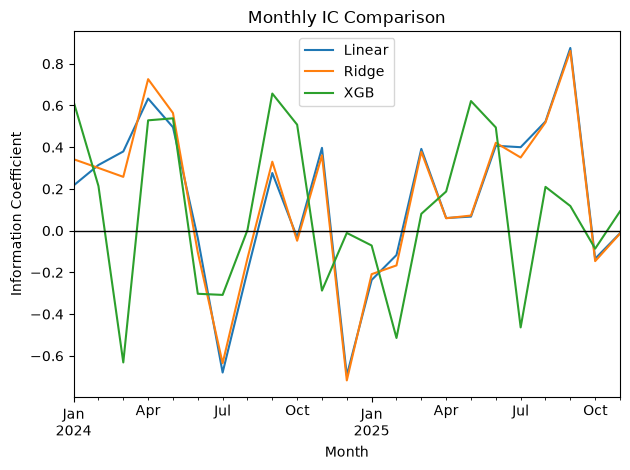

In [63]:
mics.plot()

plt.axhline(0, color="black", linewidth=1)
plt.title("Monthly IC Comparison")
plt.xlabel("Month")
plt.ylabel("Information Coefficient")
plt.legend()
plt.tight_layout()
plt.show();